# Per-metric comparison of conditions

This notebook gives the **main result** of a foci experiment. For every foci metric it answers three questions:
*does it differ between conditions, by how much, and how sure can we be?*

**Input:** the `aggregated_data.csv` of each condition and replicate, written by `agg.py`. Each file has one row per cell.
**Output:** SuperPlots, a results table with effect sizes and FDR-corrected p-values, a summary heatmap, and a check for expression-level effects.

### Workflow

| Step | Section | What it does |
|---|---|---|
| 1 | Parameters | the files, the reference condition and the metrics to test |
| 2 | Design check | how many replicates and cells each condition has |
| 3 | Quality control | missing values and cells without foci |
| 4 | SuperPlots | every metric shown cell by cell and replicate by replicate |
| 5 | Statistics | effect sizes, tests and the multiple-testing correction |
| 6 | Summary heatmap | all metrics × comparisons on one figure |
| 7 | Expression check | whether the differences are just differences in expression level |
| 8 | Reporting | how to write the result in a paper |

### Key principle: the replicate is the unit of statistics

This notebook follows the **SuperPlot** approach (Lord *et al.*, *J Cell Biol* 2020):

* plots show **every cell**, coloured by replicate, and the **median of each replicate**;
* the test that decides significance uses the **replicate medians** (*n* = number of replicates), so you need **at least 3 biological replicates per condition**;
* the cell-level test is still reported, but only as a description of the data.

A *biological replicate* is an independent repetition of the whole experiment: a separate transfection, day or coverslip.
Several images from one dish are **not** replicates.

In [1]:
%matplotlib inline
from METRICS_utils import *

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# 1. Parameters

### `data`: one entry per condition × replicate

* `condition`: the label shown on the plots. The order of first appearance sets the order on the x-axis.
* `replicate`: the replicate ID within that condition (`"1"`, `"2"`, …). Use the same IDs across conditions when the replicates were done together (e.g. day 1 = replicate 1 of every condition); then the colours match between conditions.
* `path`: the `aggregated_data.csv` of that condition and replicate.

All files must come from the **same segmentation method** (Otsu *or* GMM) and the **same parameters**. Otherwise you compare segmentations, not biology.

### Comparisons

* `COMPARISONS = "vs_reference"` compares each condition with `REFERENCE`, usually the control. It needs fewer tests, so it has more power.
* `COMPARISONS = "all_pairs"` compares every pair of conditions.

In [2]:

# Root directory where the data is stored
DATA_DIR = "/mnt/c/users/helen/Desktop/data"   # folder that holds the condition subfolders (WT/, MGS3/, ...)

# One entry per condition x replicate. Template for 3 replicates:
#   {"condition": "WT", "replicate": "1", "path": f"{DATA_DIR}/WT/rep1/gmm/aggregated_data.csv"},
#   {"condition": "WT", "replicate": "2", "path": f"{DATA_DIR}/WT/rep2/gmm/aggregated_data.csv"},
#   {"condition": "WT", "replicate": "3", "path": f"{DATA_DIR}/WT/rep3/gmm/aggregated_data.csv"},
data = [
    {"condition": "WT", "replicate": "1", "path": f"{DATA_DIR}/WT/gmm/aggregated_data.csv"},
    {"condition": "WT, NC", "replicate": "1", "path": f"{DATA_DIR}/WT_NC/gmm/aggregated_data.csv"},
    {"condition": "WT, Apt.3", "replicate": "1", "path": f"{DATA_DIR}/WT_Apt3/gmm/aggregated_data.csv"},
    {"condition": "MGS3", "replicate": "1", "path": f"{DATA_DIR}/MGS3/gmm/aggregated_data.csv"},
    {"condition": "MGS3, NC", "replicate": "1", "path": f"{DATA_DIR}/MGS3_NC/gmm/aggregated_data.csv"},
    {"condition": "MGS3, Apt.3", "replicate": "1", "path": f"{DATA_DIR}/MGS3_Apt3/gmm/aggregated_data.csv"},
]

COMPARISONS = "all_pairs"   # "vs_reference" or "all_pairs"
REFERENCE = "WT"               # baseline condition for "vs_reference"
ALPHA = 0.05                   # significance level for the FDR-corrected q-values
N_BOOT = 1000                  # bootstrap iterations for the confidence intervals of the ratios
SAVE_RESULTS = True
output_dir = Path(DATA_DIR) / "metrics_comparison"   # tables and figures are saved here

### Metrics to test

The metrics are grouped by the biological question they answer. Comment a metric out to leave it out.
Every metric in this list is one test, and the multiple-testing correction gets stricter with each one.
Prefer a focused list of metrics that answer your question over "everything".

| Group | Metric | Meaning | LLPS interpretation |
|---|---|---|---|
| **Amount of phase separation** | `n_foci` | number of foci in the cell | more nucleation |
| | `foci_density` | foci per px of nucleus | as `n_foci`, corrected for nucleus size |
| | `area_fraction` | foci area / nucleus area | ≈ volume fraction of the dense phase |
| | `fraction_signal_in_foci` | foci intensity / nucleus intensity | fraction of the protein in the condensed phase |
| | `partition_coefficient` | focus intensity / nucleoplasm intensity | how strongly the protein is enriched in foci (driving force) |
| **Focus properties** | `area` | focus size (px) | droplet size, growth or coarsening |
| | `eccentricity` | 0 = circle, toward 1 = elongated | liquid droplets are round |
| | `solidity` | area / convex hull area | irregular outline means gel- or aggregate-like |
| | `size_gini` | inequality of focus sizes in the cell | high = a few large foci and many small ones (coarsening) |
| **Spatial organisation** | `clark_evans_ratio` | < 1 clustered, ≈ 1 random, > 1 evenly spaced | nucleation at specific sites vs. mutual depletion |
| | `nn_gap` | edge-to-edge distance to the nearest focus (px) | how close foci come to each other |
| | `fraction_touching` | fraction of foci touching another focus | contacts and fusion (with watershed it also counts split foci) |

Left out on purpose:

* `mean_intensity`, `max_intensity`, `min_intensity` depend on expression level and on imaging settings, so they aren't foci properties.
* `equivalent_diameter_area` and `perimeter` duplicate `area`.
* `nn_distance` mostly duplicates `foci_density`.
* `nucleus_mean_intensity` (expression level) is used in section 7, not tested as a result.

### Minimum number of foci (`MIN_FOCI`)

Some metrics are only meaningful when a cell has several foci. With 2 foci, `size_gini` and `clark_evans_ratio` are mostly noise.
In cells with fewer foci than `MIN_FOCI`, the metric is set to *missing*. Those cells still count for every other metric.

In [ ]:
metric_groups = {
    "LLPS": [
        "n_foci",
        "foci_density",
        "area_fraction",
        "fraction_signal_in_foci",
        "partition_coefficient",
    ],
    "Focus properties": [
        "area",
        "eccentricity",
        "solidity",
        "size_gini",
    ],
    "Spatial organisation": [
        "clark_evans_ratio",
        "nn_gap",
        "fraction_touching",
    ],
}
metrics = [m for group in metric_groups.values() for m in group]

# Cells with fewer foci than this get no value for the metric
MIN_FOCI = {
    "size_gini": 4,
    "clark_evans_ratio": 4,
    "nn_gap": 2,
    "fraction_touching": 2,
}

# Metrics shown on a log axis (right-skewed and always > 0)
LOG_METRICS = ["area", "partition_coefficient"]

# Y-axis labels (units)
labels = {
    "n_foci": "foci per cell",
    "foci_density": "foci / px",
    "area_fraction": "fraction of nucleus",
    "fraction_signal_in_foci": "fraction of signal",
    "partition_coefficient": "focus / nucleoplasm",
    "area": "px (median per cell)",
    "eccentricity": "0 = circle",
    "solidity": "1 = convex",
    "size_gini": "0 = equal sizes",
    "clark_evans_ratio": "<1 clustered, >1 even",
    "nn_gap": "px (median per cell)",
    "fraction_touching": "fraction of foci",
    "nucleus_mean_intensity": "grey values",
}

# 2. Load the data and check the design

The table shows the number of cells per condition and replicate.

* **Replicates.** With fewer than 2 replicates in any condition, only cell-level tests are possible. The notebook warns about it: treat those p-values as descriptive.
* **Balance.** Very different cell numbers between replicates are fine for the replicate-level test, because each replicate counts once. In the pooled cell-level numbers, however, a big replicate dominates.
* **`cells_without_foci`.** Cells with no foci are kept. They count as 0 for `n_foci`, `foci_density`, `area_fraction` and `fraction_signal_in_foci`, and they have no value for the per-focus metrics.

In [4]:
df = load_conditions(data)
df = apply_min_foci(df, MIN_FOCI)
TEST_LEVEL = check_design(df)
q_col = "q_replicates" if TEST_LEVEL == "replicates" else "q_cells"
print(f"Significance is taken from: {q_col}")

design_table(df)

  Replicate-level tests are impossible. Only cell-level tests are
  computed: their p-values treat every cell as independent and
  overstate significance. Use them as descriptive only.
Significance is taken from: q_cells


,rep 1,n_replicates,n_cells,cells_without_foci
condition,,,,
WT,36,1,36,0
"WT, NC",41,1,41,0
"WT, Apt.3",38,1,38,0
MGS3,26,1,26,0
"MGS3, NC",58,1,58,0
"MGS3, Apt.3",79,1,79,0


# 3. Quality control: missing values

The table gives the **fraction of cells with no value** for each metric, by condition. Values are missing for cells without foci, cells below `MIN_FOCI`, or metrics absent from an older `agg.py` output.

What to look for:

* **A whole column at 1.0**: the metric isn't in that condition's file. Rerun `outsu.py`/`gmm.py` and `agg.py` with the current version.
* **Very different fractions between conditions**: for example, the control has many cells without foci and the mutant has few. The per-focus metrics are then computed on a selected subset of cells, so report the fraction of cells with foci too.

Before going further, also open a few `panels/` overlays from each condition and check that the segmentation is correct. No statistics can repair a wrong segmentation.

In [5]:
missing_table(df, metrics)

condition,WT,"WT, NC","WT, Apt.3",MGS3,"MGS3, NC","MGS3, Apt.3"
n_foci,0.0,0.0,0.0,0.0,0.0,0.00
foci_density,0.0,0.0,0.0,0.0,0.0,0.00
area_fraction,0.0,0.0,0.0,0.0,0.0,0.00
fraction_signal_in_foci,0.0,0.0,0.0,0.0,0.0,0.00
partition_coefficient,0.0,0.0,0.0,0.0,0.0,0.00
area,0.0,0.0,0.0,0.0,0.0,0.00
eccentricity,0.0,0.0,0.0,0.0,0.0,0.00
solidity,0.0,0.0,0.0,0.0,0.0,0.00
size_gini,0.0,0.0,0.0,0.0,0.0,0.01
clark_evans_ratio,0.0,0.0,0.0,0.0,0.0,0.01


# 4. SuperPlots

There is one panel per metric:

* **small dots**: individual cells, coloured by replicate;
* **large dots with black edges**: the **median of each replicate**, the values the statistics are based on;
* **black bar**: mean of the replicate medians; **error bar**: SD between replicates.

How to read them:

* If the large dots of two conditions **don't overlap**, the effect is consistent between experiments.
* If one replicate sits far from the others in every condition, it is a **batch effect**, e.g. a different day or a different transfection efficiency. The replicate-level test handles it correctly.
* If the cell clouds differ only because of one replicate, the difference is not reproducible.

Stars above a condition (added in section 5) are FDR-corrected q-values vs. the baseline: `*` < 0.05, `**` < 0.01, `***` < 0.001, `ns` not significant.

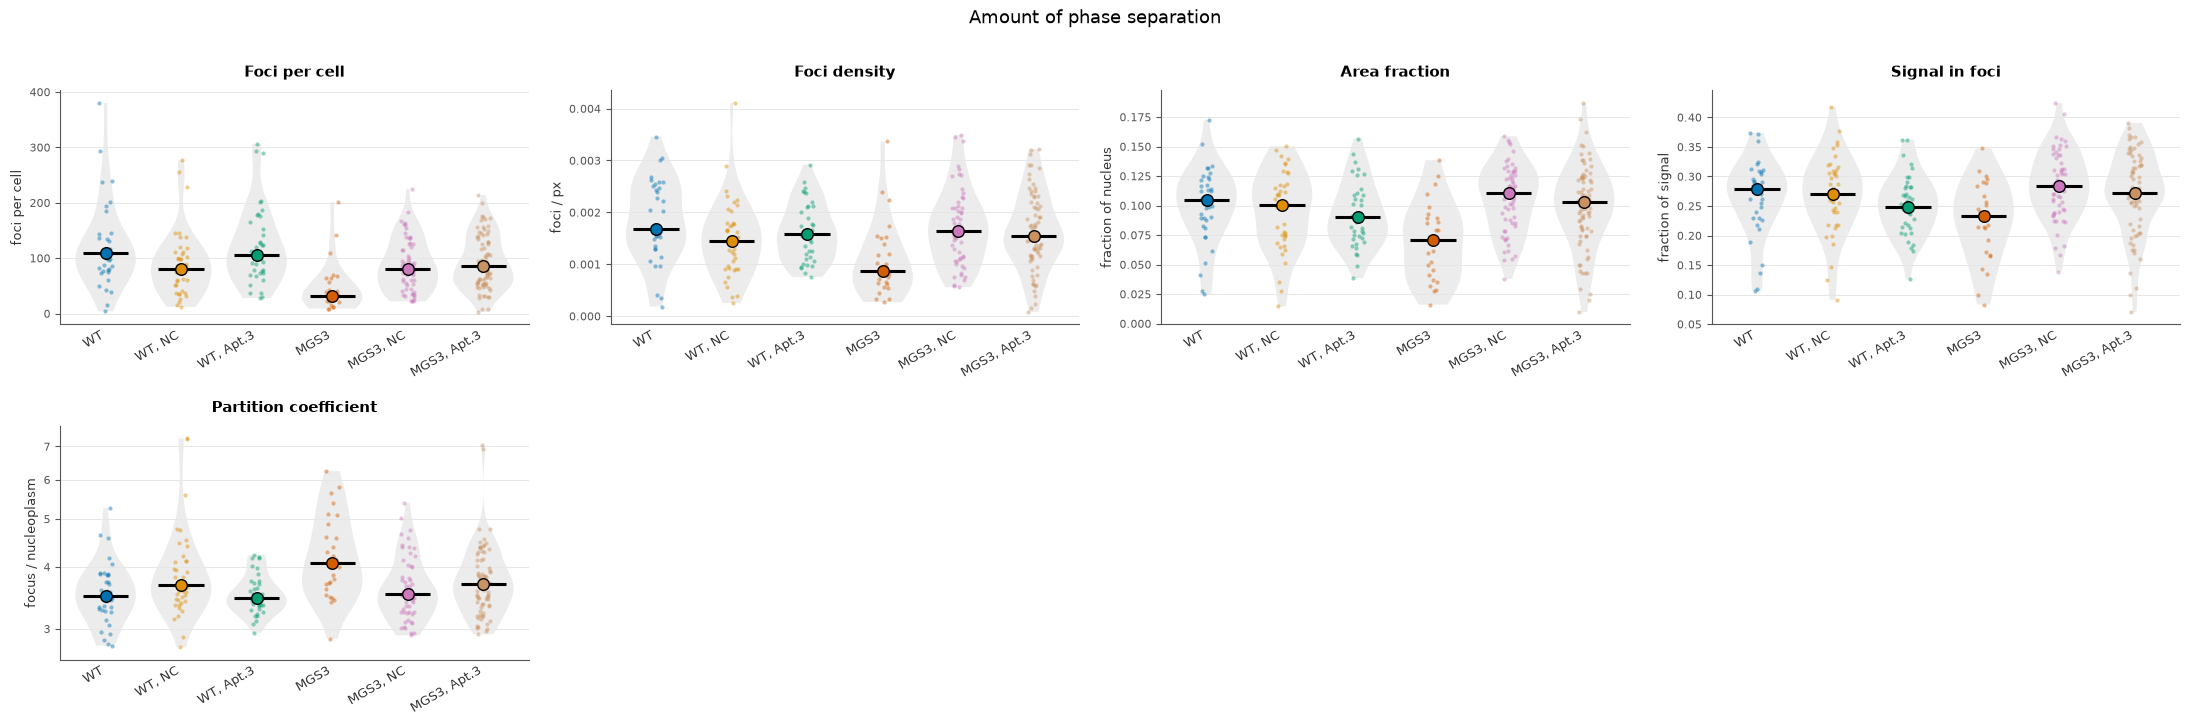

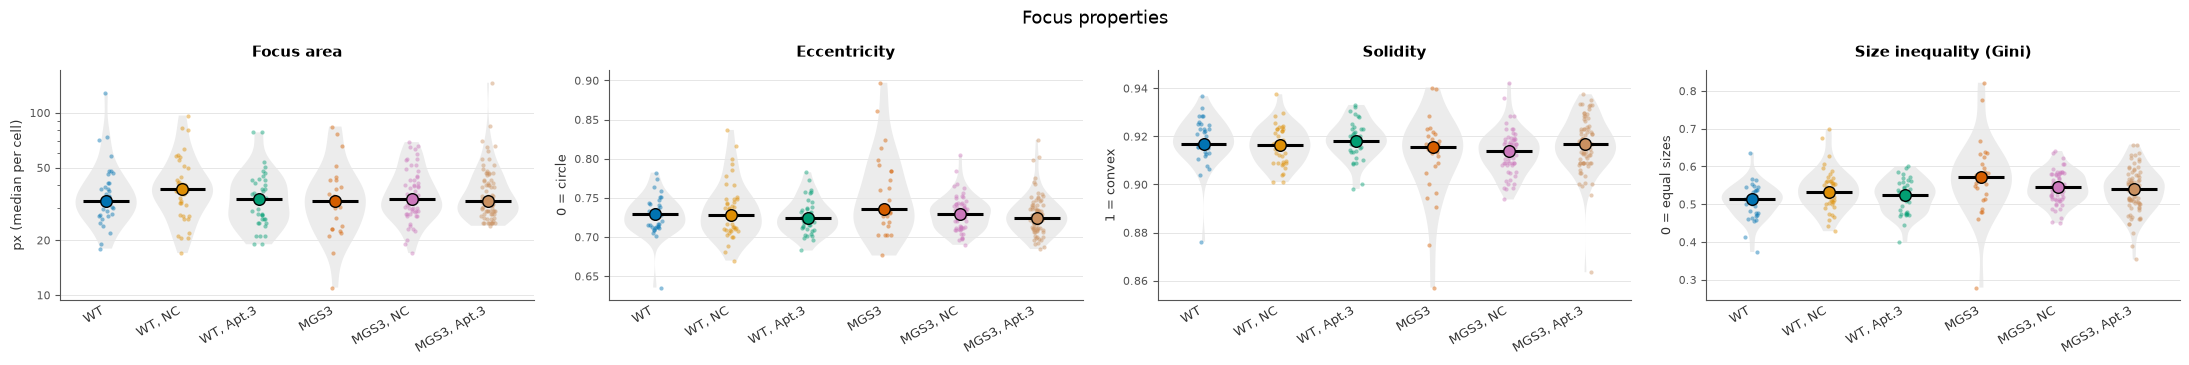

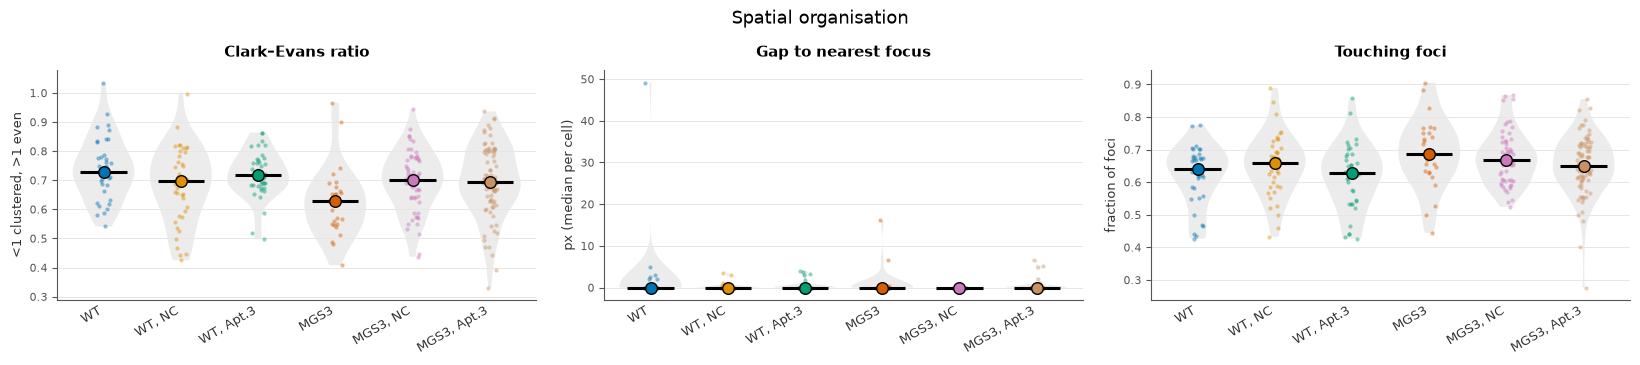

In [6]:
for group, group_metrics in metric_groups.items():
    fig = plot_superplots(df, group_metrics, labels=labels, log_metrics=LOG_METRICS)
    fig.suptitle(group, y=1.06, fontsize=13)
    plt.show()

# 5. Statistics

### What is computed for each metric × comparison

| Column | Meaning |
|---|---|
| `median`, `median_baseline` | median over all cells of the condition and of its baseline |
| `ratio` | `median / median_baseline`: 1.5 means 50 % higher than the baseline |
| `ratio_ci_low`, `ratio_ci_high` | 95 % confidence interval of the ratio from a **hierarchical bootstrap**, which resamples replicates and then cells within replicates, so the CI includes the variability between experiments. It is empty when the baseline median is often 0 |
| `cliffs_delta` | rank-based effect size from −1 to 1: the probability that a random cell of the condition has a higher value than a random baseline cell, minus the reverse. 0 = no difference; \|δ\| ≈ 0.15 small, 0.33 medium, 0.47 large |
| `p_replicates`, `q_replicates` | Welch *t*-test on the **replicate medians**, and its FDR-corrected q-value. **Base conclusions on this one.** |
| `p_cells`, `q_cells` | Mann–Whitney *U* test on all cells, and its q-value. **Descriptive only**: it treats cells as independent, so it is far too optimistic |

### Why these tests

* **Replicate medians with Welch's *t*-test.** With 3–6 replicates, the medians are close to normally distributed, and Welch's test doesn't assume equal variances. It is equivalent in spirit to a mixed model `metric ~ condition + (1 | replicate)`, but simpler and more robust with few replicates.
* **Medians, not means.** Foci metrics are skewed: a few huge foci or bright cells would dominate a mean.
* **Cliff's delta with a ratio.** The ratio is easy to interpret ("foci are 1.8× larger"). Cliff's delta works on any metric, including metrics that are often 0 (`nn_gap`), and it is comparable across metrics, which the summary heatmap needs.

### Multiple testing

With 12 metrics × 5 comparisons = 60 tests, about 3 would be "significant" at p < 0.05 by chance alone.
**Benjamini–Hochberg** correction controls the false discovery rate: among the results called significant at q < 0.05, at most 5 % are expected to be false.
The correction is applied over **all metrics and comparisons together**.

**First, the omnibus test:** is there any difference among all conditions for this metric?

In [ ]:
omnibus = omnibus_tests(df, metrics)
omnibus.round(4)

**Pairwise comparisons:**

In [ ]:
pairs = comparison_pairs(df["condition"].cat.categories, reference=REFERENCE, mode=COMPARISONS)
results = compare_metrics(df, metrics, pairs, n_boot=N_BOOT)
results["significant"] = results[q_col] < ALPHA
results["stars"] = results[q_col].map(stars)

show = ["metric", "condition", "baseline", "n_rep", "n_rep_baseline", "n_cells", "n_cells_baseline",
        "median", "median_baseline", "ratio", "ratio_ci_low", "ratio_ci_high", "cliffs_delta",
        "p_replicates", "q_replicates", "p_cells", "q_cells", "stars"]
# Significant rows (q < ALPHA) are marked with stars; "ns" = not significant
results[show].round(4)

### SuperPlots with significance

These are the same plots as in section 4, now with the q-values used for conclusions (`q_replicates`, or `q_cells` when there are no replicates).

In [ ]:
for group, group_metrics in metric_groups.items():
    fig = plot_superplots(df, group_metrics, labels=labels, log_metrics=LOG_METRICS,
                          results=results, q_col=q_col)
    fig.suptitle(group, y=1.06, fontsize=13)
    if SAVE_RESULTS:
        output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_dir / f"superplots_{group.replace(' ', '_').lower()}.png",
                    dpi=300, bbox_inches="tight")
    plt.show()

# 6. Summary heatmap

Every metric × comparison is shown on one figure. **Colour = Cliff's delta**: red means higher than the baseline, blue lower, white no difference. **Stars** come from the q-values.

It shows at a glance *which aspects* of phase separation a condition changes, e.g. "more foci and more protein in foci, but the same droplet properties".
Read the colour and the stars together. A deep colour without stars means a large but inconsistent effect, which usually needs more replicates. A pale colour with stars means a small but very reproducible effect.

In [ ]:
fig = plot_effect_heatmap(results, q_col=q_col, metrics=metrics)
if SAVE_RESULTS:
    fig.savefig(output_dir / "effect_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# 7. Expression-level check

In LLPS, almost every foci metric depends on **how much protein the cell contains**. Above the saturation concentration, more protein means more and larger foci.
If a mutant simply expresses more than the wild type, it will have "more foci" even when its phase behaviour is identical.

Three checks, using `nucleus_mean_intensity` (mean raw intensity of the nucleus) as the expression level:

1. **Do the conditions differ in expression?** If not, the metric differences can't be explained by expression.
2. **Which metrics depend on expression?** The table gives the Spearman ρ between each metric and expression in each condition. |ρ| > 0.3 is a clear dependence.
3. **Expression-matched comparison:** the statistics are repeated using only the cells whose expression lies in the range shared by all conditions (between the highest 5th percentile and the lowest 95th percentile). A difference that **survives matching** is a real change in phase behaviour. One that **disappears** was driven by expression.

Mean intensity compares expression only when all conditions were imaged with the **same microscope settings** (laser power, gain, exposure).

In [ ]:
EXPR = "nucleus_mean_intensity"
if EXPR not in df.columns:
    raise KeyError(f"{EXPR} is missing: rerun agg.py with the current version.")

fig = plot_superplots(df, [EXPR], labels=labels, ncols=1, height=3.5)
plt.show()

expr_res = compare_metrics(df, [EXPR], pairs, n_boot=N_BOOT)
expr_res[["condition", "baseline", "median", "median_baseline", "ratio", "cliffs_delta",
          "p_replicates", "p_cells"]].round(4)

In [ ]:
rho = expression_correlation(df, metrics, expr_col=EXPR)
rho

In [ ]:
df_matched, (lo, hi) = expression_matched(df, expr_col=EXPR)
print(f"Shared expression range: {lo:.1f} to {hi:.1f}; "
      f"{len(df_matched)} of {len(df)} cells kept")
display(design_table(df_matched))

results_matched = compare_metrics(df_matched, metrics, pairs, n_boot=N_BOOT)

robust = results[["metric", "condition", "baseline", "cliffs_delta", q_col]].merge(
    results_matched[["metric", "condition", "baseline", "cliffs_delta", q_col]],
    on=["metric", "condition", "baseline"], suffixes=("_all", "_matched"))
sig_all = robust[f"{q_col}_all"] < ALPHA
sig_matched = robust[f"{q_col}_matched"] < ALPHA
# Effect preserved: same direction and at least half of the original Cliff's delta
d_all, d_matched = robust["cliffs_delta_all"], robust["cliffs_delta_matched"]
preserved = (np.sign(d_all) == np.sign(d_matched)) & (d_matched.abs() >= 0.5 * d_all.abs())
robust["verdict"] = np.select(
    [sig_all & sig_matched,
     sig_all & ~sig_matched & preserved,
     sig_all & ~sig_matched & ~preserved,
     ~sig_all & sig_matched],
    ["robust to expression",
     "effect size preserved, fewer cells after matching",
     "effect shrinks after matching: expression-driven?",
     "only after matching"],
    default="ns")
robust.round(3)

How to read the `verdict` column:

* **robust to expression**: the difference is still significant at equal expression. This is the strongest evidence of a change in phase behaviour.
* **effect size preserved, fewer cells after matching**: Cliff's δ stays similar (same direction, at least half its original size), but the q-value rises because matching removed cells. The effect is most likely real and not caused by expression.
* **effect shrinks after matching: expression-driven?**: δ drops by more than half or changes sign. The difference is largely explained by different expression levels.
* **only after matching**: a difference was hidden by the different expression ranges.

Compare `cliffs_delta_all` with `cliffs_delta_matched` yourself as well. The effect size tells you more than whether q crosses 0.05.

For a quantitative version, the saturation concentration (c_sat) can be estimated from where foci appear as expression increases. That analysis is outside this notebook.

# 8. Save and report

In [ ]:
if SAVE_RESULTS:
    output_dir.mkdir(parents=True, exist_ok=True)
    results.to_csv(output_dir / "metric_comparisons.csv", index=False)
    omnibus.to_csv(output_dir / "omnibus_tests.csv", index=False)
    robust.to_csv(output_dir / "expression_matched_comparison.csv", index=False)
    design_table(df).to_csv(output_dir / "design.csv")
    print(f"Saved to {output_dir}")

### Reporting checklist

For a figure legend or a methods section, give:

* **n:** the number of biological replicates per condition, and the total number of cells, e.g. *"n = 3 independent experiments, 142–210 cells per condition"*.
* **The plot:** *"SuperPlot: small dots are cells coloured by experiment, large dots are experiment medians, bars are mean ± SD of experiment medians."*
* **The test:** *"Welch's t-test on experiment medians vs. WT, with Benjamini–Hochberg correction over all metrics and comparisons."*
* **The effect size:** the ratio with its 95 % CI, e.g. *"partition coefficient 1.8× higher (95 % CI 1.4–2.3)"*. It is more informative than the p-value alone.
* **The segmentation:** method and parameters, i.e. the `run_config.toml` of the runs.
* **The expression control:** *"the difference persisted in expression-matched cells"* (section 7).

Example sentence:
> *Mutant MGS3 increased the fraction of nuclear signal in foci 2.1-fold (95 % CI 1.6–2.7; q = 0.004, n = 4 experiments), without changing focus size (q = 0.62). The effect persisted in expression-matched cells.*